# Material de aula - FACENS - Aprendizado de Máquina


## RBF- Laboratório 03

In [1]:
#CÉLULA RBF-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [2]:
#CÉLULA RBF-LIB-02
def euclidean_distance(v1, v2) :
    '''
    Esta função recebe 2 arrays (do tipo np.array) e retorna a distância euclidiana entre eles
    
    Parâmetros
    ----------
    v1 -> vetor de coordenadas do primeiro ponto
    v2 -> vetor de coordenadas do segundo ponto
    
    Retorno
    -------
    Distância entre os dois pontos    
    '''
    return np.sqrt( sum((v1 - v2)**2) )

In [3]:
#CÉLULA RBF-LIB-03
def calcBestK(N) :
    '''
    Calcula, a título de "chute inicial", um valor para o número de clusters (K)
    
    Parametros
    ----------
    N -> número de amostras disponiveis
    
    Retorno
    -------
    Número de clusters a serem usados
    '''
    return np.sqrt(N/2)

In [4]:
v1 = np.array([1,1])
v2 = np.array([4,5])
euclidean_distance(v1,v2)

5.0

In [5]:
#CÉLULA RBF-LIB-04
def plot_cluster(vInputs, vOutputs, W_1, sigma) :
    '''
    Plota o gráfico do cluster gerado pelo k-means e os raios de cada um.
    
    Parametros
    -----------
    vInputs   -> vetor/matriz com dados observados
    vOutputs  -> vetor/matriz com as saidas
    W_1       -> array com os centroides
    sigma     -> raio do cluster 
    
    '''
    c1X = []
    c1Y = []
    c2X = []
    c2Y = []
    for k in range(len(vInputs)) :
        if( vOutputs[k] == 1 ):
            c1X.append(np.asscalar(vInputs[k][0]))
            c1Y.append(np.asscalar(vInputs[k][1]))
        else:
            c2X.append(np.asscalar(vInputs[k][0]))
            c2Y.append(np.asscalar(vInputs[k][1]))

    fig = plt.figure(figsize=(10,10))
    plt.grid()
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.title('Clusters - RBF')
    plt.plot(c1X, c1Y, 'bx')
    plt.hold(True)
    plt.plot(c2X, c2Y, 'ro')
    
    #Plota os centroides
    plt.plot( W_1[:, 0], W_1[:, 1], 'k+')
    
    angle = np.arange(0, 2*np.pi, 0.01)
    for i in range( np.shape(W_1)[0]) :
        r = sigma[i]
        x = W_1[i][0]
        y = W_1[i][1]
        xp=r*np.cos(angle)
        yp=r*np.sin(angle)
        plt.plot(x+xp,y+yp, 'k')    

In [6]:
#CÉLULA RBF-LIB-05
def kmeans(vData, nClusters) :
    '''
    Este método calcula os centroides dos clusters de um conjunto de dados a partir do algoritmo k-means
    
    Parâmetros
    ----------
    vData -> vetor de coordenadas N-Dimensionais dos dados. Cada posição do array deve ser uma lista de coordenadas
        
    Retorno
    -------
    Array contendo a lista de pontos observados, onde cada posição do array corresponde a um clusterId. 
    Cada ponto do array de retorno é definido como um dicionário com a seguinte estrutura:
        {
         'pointCoord'  : coordenadas do ponto, 
         'centerCoord' : coordenadas de seu centroide, 
         'clusterId'   : identificador do cluster
        }
    '''

    #Inicializa os centroides
    vClusterCenters = [vData[i] for i in range(0, nClusters)]
    
    vPoints = [{'point':point, 'clusterId' : -1, 'centerCoord' : point*0} for point in vData] #tupla (point, clusterCentroid)
    
    clusterIsChanging = True
    while(clusterIsChanging == True) :
    
        clusterIsChanging = False

        vClusterPoints  = [[]] * nClusters #cria lista de listas com tamanho nClusters. O indice primario corresponde a cada cluster

        for dataPoint in vPoints :
            vDistances = [ euclidean_distance(dataPoint['point'], center) for center in vClusterCenters ]
            clusterIndex = np.argmin(vDistances)

            if( dataPoint['clusterId'] != clusterIndex ) :
                dataPoint['clusterId']  = clusterIndex
                clusterIsChanging = True

        #Após a redistribuição dos pontos, recalcula os centroides
        for clusterIndex, clusterCenter in enumerate(vClusterCenters) :
            clusterData = [ point['point'] for point in vPoints if point['clusterId'] == clusterIndex ]
            vClusterCenters[clusterIndex] = np.mean(clusterData, axis=0) #atualiza centroide do cluster indicado pelo clusterIndex

    
    for dataPoint in vPoints :
        dataPoint['centerCoord'] = vClusterCenters[dataPoint['clusterId']]
                    
    return (vPoints, vClusterCenters)

In [7]:
#CÉLULA RBF-LIB-06
def cluster_distortion(vDataPoints, nClusters, bWeighted = False) :
    '''
    Esta função calcula a distorção intra-cluster
    
    Parâmetros
    ----------
    vDataPoints -> array contendo os pontos (dados observados). Cada ponto é definido como um dicionário com a seguinte estrutura
        {'pointCoord' : coordenadas do ponto, 'centerCoord' : coordenadas de seu centroide, 'clusterId' : identificador do cluster}
    
    nClusters   -> quantidade de clusters utilizados
    bWeighted   -> Se for definido como True, cada distorção será ponderada pelo numero de dados do cluster, resultando no 
                   cálculo da distância média quadrática (ou variância da função de ativação da RBF).
    
    Retorno
    -------
    
    Um array contendo a distorção intra-cluster de todos os clusters, onde cada posição do array corresponde ao clusterId    
    '''
    
    vClusterDist = []
    for i in range(nClusters) :
        vClusterPoints = [point for point in vDataPoints if point['clusterId'] == i]
        distance = sum([euclidean_distance(point['point'], point['centerCoord'])**2 for point in vClusterPoints])

        if( bWeighted == True) :
            distance /= len(vClusterPoints)
        
        vClusterDist.append(distance)
    
    return vClusterDist    

In [8]:
#CÉLULA RBF-LIB-07
def loadDataFile(strFileName) :
    '''
    Esta função carrega os dados de um arquivo e retorna um dataframe
    '''
    return pd.read_csv(strFileName)    

In [9]:
#CÉLULA RBF-LIB-08
def avgSquaredError(x, d, W_2) :
    '''
    Calula o Erro Quadratico Medio (ASE)
    
    Parametros
    ----------
    x   -> array de dados da entrada
    d   -> array de dados de saída
    W_2 -> pesos conectando as camadas de entrada e saida
    
    Retorno
    -------
    Valor do EQM para uma época de treinamento.    
    '''
    nSamples = np.shape(x)[1]
    I_2 = np.matmul(W_2, x)
    Y_2 = I_2 #Função de ativação linear
    
    #IMPLEMENTE O CÓDIGO ABAIXO
    E_k = (d - Y_2)**2
    E_k = np.sum(E_k, axis=0) / 2 #soma os elementos de cada coluna entre si
    ASE = sum(E_k) / nSamples # totaliza os elementos do array fazendo a media
    
    return ASE

In [10]:
#CÉLULA RBF-LIB-09
def rbf_stage1_training(vInputs, nHiddenLayer) :
    '''
    Realiza a fase 1 do treinamento da RBF.
    Espera-se x no formato [ neuronios x amostras ] de modo que a quantidade de neurons da camada oculta está nas linhas da 
    matriz x    
    '''
    (vPoints, vClusterCenters) = kmeans(vInputs, nHiddenLayer) 

    W_1 = np.array(vClusterCenters) #array de nClusters (linhas) por x entradas (colunas)

    #distorção de cada cluster = campo hiperesferico do neuronio da camada oculta = variancia
    #print(vClusterDist)
    clusterDist = cluster_distortion(vPoints, nHiddenLayer, True)
    sigmaSquared = np.array(clusterDist)

    return (W_1, sigmaSquared)

# 1 - Implemente o calculo do estágio 1 de operação da RBF

In [12]:
#CÉLULA RBF-LIB-10
def rbf_stage1_operation(vInputs, c, wVar) :
    '''Algoritmo de operação do RBF - Estagio 1
    
    Parametros
    -----------
    vInputs  : vetor/matriz com as entradas
    c        : vetor/matriz com os pesos
    wVar     : variância dos pesos
    
    Retorno
    -------
    Este método retorna o array de saida [amostras x neuronios] de saída do primeiro estágio da RBF calculado segundo 
    sua função de ativação gaussiana. Cada linha corresponde a uma amostra enquanto cada coluna corresponde a um neurônio da 
    camada oculta
    ''' 

    nSamples = len(vInputs)
    nNeurons = len(c)
    
    #Calcula saída da camada intermediária da RBF
    g = []
    for k in range(nSamples) :
        u = vInputs[k]
        z = (u-c)**2
        num = np.sum(z,axis=1)
        den = 2 * sigmaSquared
        g.append(np.exp(-num/den))

    return np.array(g)

In [13]:
#CÉLULA RBF-LIB-11
def rbf_stage2_training(eta, epsilon, vInputs, vOutputs, max_epochs, outLayerSize):
    '''
    Realiza a fase 2 do treinamento da RBF.
    Espera-se x no formato [ neuronios x amostras ] de modo que a quantidade de neurons da camada oculta está nas linhas da 
    matriz x
    '''
    
    nHiddenNeurons = np.shape(vInputs)[0]    
    nSamples = np.shape(vInputs)[1]
    W_2 = np.random.rand(outLayerSize, nHiddenNeurons)    
   
    vASE = []    
    currentASE = avgSquaredError(vInputs, vOutputs, W_2)
    #Guarda EQM atual
    vASE.append(currentASE)
        
    for epochCounter in range(1, max_epochs) :
        for k in range(nSamples) :
            #Forward Step - INICIO
            X = vInputs[:, [k]]
            d = vOutputs[:, [k]]
            
            I_2 =np.matmul(W_2, X)
            Y_2 = I_2 #função de ativação linear
            #Forward Step - FIM
        
            #Backward Step - INICIO
            delta_2 = d - Y_2 #gradiente da função linear é apenas a diferença entre valores
                        
            #Correção de pesos da camada de saída
            for j in range(outLayerSize) : #cada linha é um neuron de saida
                for i in range(nHiddenNeurons) : #cada coluna é uma sinapse com os neurons da camada oculta
                    W_2[j][i] += eta * delta_2[j] * X[i]
            #Backward Step - FIM
        
        #Fim do loop de amostras (época), calcula o erro
        currentASE = avgSquaredError(vInputs, vOutputs, W_2)
        #Guarda EQM atual
        vASE.append(currentASE)
        
        #Verifica criterio de parada, por convergência
        if( abs(vASE[epochCounter] - vASE[epochCounter-1]) <= epsilon ) :
            break
            
    return (W_2, vASE, epochCounter+1)        

In [29]:
#CÉLULA RBF-LIB-12
def rbf_stage2_operation(X, W_2):
    '''
    Espera-se x no formato [ neuronios x amostras ] de modo que a quantidade de neurons da camada oculta está nas linhas da 
    matriz x
    
    Espera-se W_2 no formato [ neuronios x sinapses] de modo que cada linha corresponde a um neuronio e cada coluna a uma sinapse
    '''    
    I_2 = np.matmul(W_2, X)
    Y_2 = I_2 #Função de ativação linear

    return Y_2

# RBF - Início

## A verificação da presença de radiação em determinados compostos nucleares pode ser feita por intermédio da análise da concentração de duas variáveis definidas por x1 e x2 . A partir de 50 situações conhecidas, resolveu-se então treinar uma RBF para a execução da tarefa de classificação de padrões neste processo, cuja topologia está ilustrada na figura seguinte.

![image.png](attachment:image.png)

## A padronização para a saída, a qual representa a presença ou ausência de sinais de radiação, ficou definida da seguinte forma:


| Status de Radiação | Saída (y) |
|--------------------|-----------|
|     Presença       |    1      |
|     Ausência       |   -1      |


## Utilizando os dados de treinamento apresentados nos arquivos, execute o treinamento deuma RBF (2 entradas e 1 saída) que possa classificar, em função apenas dos valores medidos de x1 e x2, se determinado composto possui radiação. Utilize uma taxa de aprendizado $ \eta = 0.01$ e precisão de $ \epsilon = 10^-7 $. 

In [30]:
#CÉLULA RBF-MAIN-01

#Parâmetros
max_epochs = 10000
eta = 0.01; #coeficiente de treinamento
epsilon = 1e-07; # margem do erro
layersDescriptor = {'input' : 2, 'hidden' : 5, 'output' : 1} #descritor das camadas da RBF

In [31]:
#CÉLULA RBF-MAIN-02

#Carrega dados de treinamento e teste
strTrainingFileName = 'Lab01_RBF_training.csv'
strOperationFileName = 'Lab01_RBF_operation.csv'

dfTrainingFile = loadDataFile(strTrainingFileName)
#dfTrainingFile.columns

dfOperationFile = loadDataFile(strOperationFileName)
#dfOperationFile.columns

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:32: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
C:\ProgramData\Anaconda3\lib\site-packages\matplotlib\__init__.py:911: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
C:\ProgramData\Anaconda3\lib\site-packages\matplotlib\rcsetup.py:156: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed in 3.0
  mplDeprecation)


Treinamento finalizado em 1131 épocas


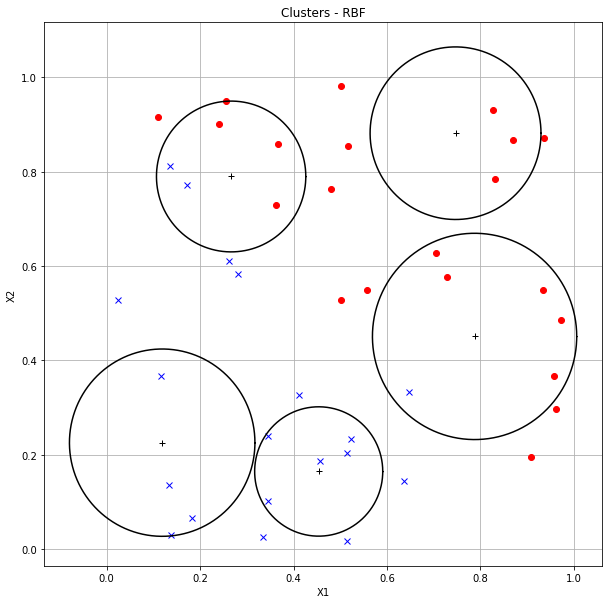

In [32]:
#CÉLULA RBF-MAIN-03
nSamples = len(dfTrainingFile)
vInputs  = np.array(dfTrainingFile.loc[: , 'x1':'x2'])
vOutputs = np.array(dfTrainingFile.loc[: , 'd'])

#PRIMEIRO ESTAGIO DE TREINAMENTO: Alocação dos neuronios da camada oculta
''' 
{
    'pointCoord'  : coordenadas do ponto, 
    'centerCoord' : coordenadas de seu centroide, 
    'clusterId'   : identificador do cluster
}
'''

(W_1, sigmaSquared) = rbf_stage1_training(vInputs, layersDescriptor['hidden'])
#print(W_1)
#print(var)

plot_cluster(vInputs, vOutputs, W_1, np.sqrt(sigmaSquared))

#PREPARAÇAO PARA SEGUNDO ESTAGIO DE TREINAMENTO
#PRIMEIRO ESTAGIO DE OPERAÇÃO
Y_1 = rbf_stage1_operation(vInputs, W_1, sigmaSquared)

# SEGUNDO ESTAGIO DE TREINAMENTO : Ajuste dos pesos da camada de saída
nSamples = Y_1.shape[0]
col0 = np.ones((nSamples, 1)) * (-1)
vInputsWithBias = np.array(col0)
vInputsWithBias = np.append(vInputsWithBias, Y_1, axis=1)
#print(vInputsWithBias.T.shape)

#Treinamento
vOutputs = np.reshape(vOutputs, (len(vOutputs),  layersDescriptor['output'])).T
(W_2, vError, nEpochs) = rbf_stage2_training(eta, epsilon, vInputsWithBias.T, vOutputs, max_epochs, layersDescriptor['output'])
print('Treinamento finalizado em {} épocas'.format(nEpochs))

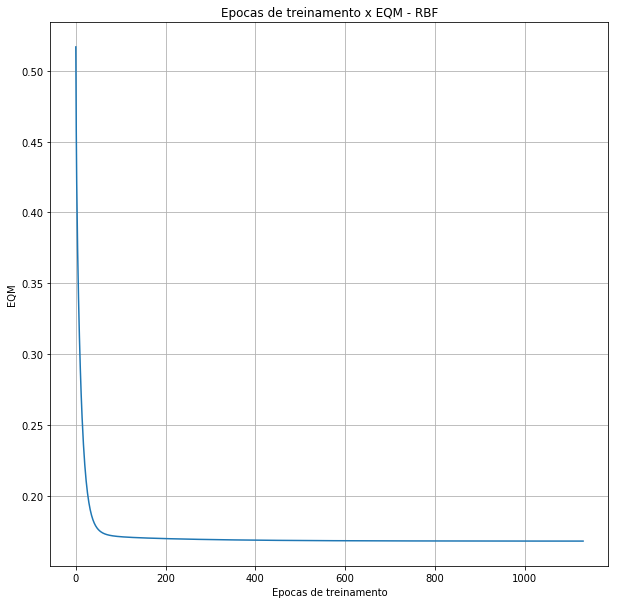

In [33]:

#CÉLULA RBF-MAIN-04
# Plotando o Erro Quadrático Médio
fig = plt.figure(figsize=(10,10))
plt.grid()
plt.xlabel('Epocas de treinamento')
plt.ylabel('EQM')
plt.title('Epocas de treinamento x EQM - RBF')
plt.plot(range(nEpochs), vError)